
# Day 04: Statistics, Splits, and Data Leakage

## Project Overview

This project focuses on statistical analysis, dataset splitting, and identifying data leakage in machine learning.

## Objectives

- Perform statistical analysis using Python.
- Understand mean, median, and variance.
- Create training, validation, and testing datasets.
- Apply stratified splitting.
- Ensure reproducibility using random states.
- Identify data leakage and duplicate contamination.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Jupyter Notebook


## 1. Dataset Loading

In [22]:
from sklearn.datasets import load_breast_cancer
from pathlib import Path

# Load dataset
dataset = load_breast_cancer(as_frame=True)

# Convert dataset into DataFrame
df = dataset.frame.copy()

# Convert target values into diagnosis names
df["diagnosis"] = df["target"].map(
    dict(enumerate(dataset.target_names))
)

# Remove original target column
df = df.drop(columns=["target"])

# Save dataset inside Day-04/data folder
data_path = Path("../data/breast_cancer.csv")
df.to_csv(data_path, index=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

Dataset loaded successfully!
Dataset Shape: (569, 31)

First 5 Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 2. Dataset Inspection

In [23]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first 5 records
print("\nFirst 5 Records:")
display(df.head())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check diagnosis distribution
print("\nDiagnosis Distribution:")
print(df["diagnosis"].value_counts())

Dataset Shape: (569, 31)

First 5 Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

## 3. Statistical Analysis

In [24]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate Mean
mean_values = numeric_df.mean()

# Calculate Median
median_values = numeric_df.median()

# Calculate Variance
variance_values = numeric_df.var()

# Calculate Standard Deviation
std_values = numeric_df.std()

# Create statistical summary
statistics = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Variance": variance_values,
    "Standard Deviation": std_values
})

print("Statistical Summary:")
display(statistics.round(2))

Statistical Summary:


,Mean,Median,Variance,Standard Deviation
mean radius,14.13,13.37,12.42,3.52
mean texture,19.29,18.84,18.50,4.30
mean perimeter,91.97,86.24,590.44,24.30
mean area,654.89,551.10,123843.55,351.91
mean smoothness,0.10,0.10,0.00,0.01
mean compactness,0.10,0.09,0.00,0.05
mean concavity,0.09,0.06,0.01,0.08
mean concave points,0.05,0.03,0.00,0.04
mean symmetry,0.18,0.18,0.00,0.03
mean fractal dimension,0.06,0.06,0.00,0.01


## 4. Data Distribution Visualization

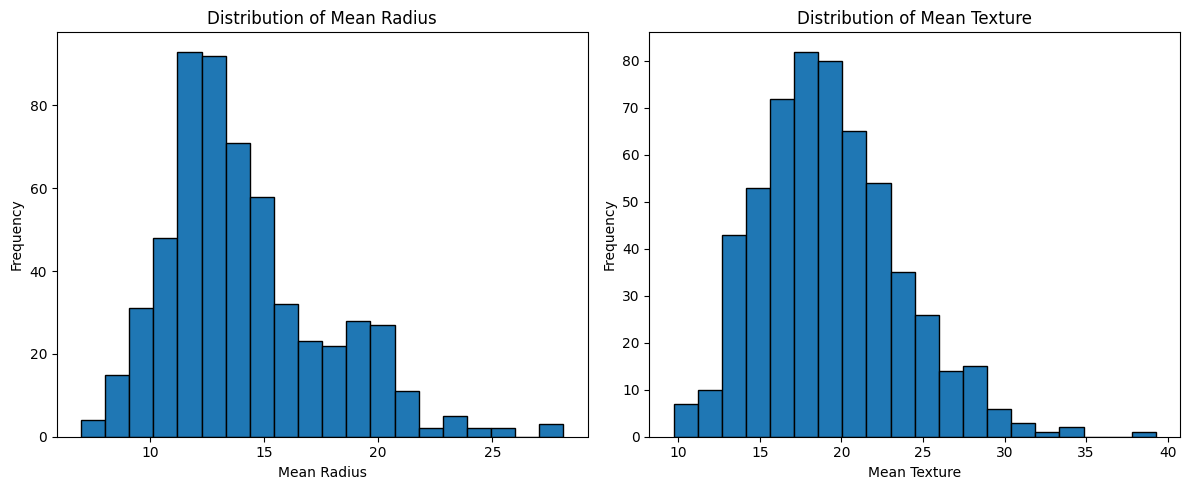

In [25]:
# Plot histogram for selected features
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df["mean radius"], bins=20, edgecolor="black")
plt.title("Distribution of Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df["mean texture"], bins=20, edgecolor="black")
plt.title("Distribution of Mean Texture")
plt.xlabel("Mean Texture")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../reports/plots/feature_distribution.png")
plt.show()

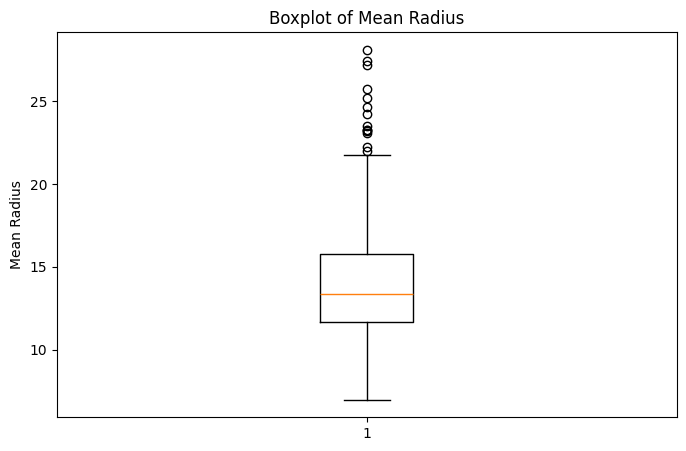

In [26]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["mean radius"])
plt.title("Boxplot of Mean Radius")
plt.ylabel("Mean Radius")

plt.savefig("../reports/plots/mean_radius_boxplot.png")
plt.show()

## 5. Train, Validation and Test Split

In [27]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes
print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nTotal Records:", len(X_train) + len(X_val) + len(X_test))

# Check class distribution
print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation Class Distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Data: (398, 30)
Validation Data: (85, 30)
Testing Data: (86, 30)

Total Records: 569

Training Class Distribution:
diagnosis
benign       0.628
malignant    0.372
Name: proportion, dtype: float64

Validation Class Distribution:
diagnosis
benign       0.624
malignant    0.376
Name: proportion, dtype: float64

Testing Class Distribution:
diagnosis
benign       0.628
malignant    0.372
Name: proportion, dtype: float64


## 6. Reproducibility Check

In [28]:
# Perform the same split again
X_train_new, X_temp_new, y_train_new, y_temp_new = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val_new, X_test_new, y_val_new, y_test_new = train_test_split(
    X_temp_new,
    y_temp_new,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_new
)

# Compare original and new splits
print("Training split identical:", X_train.equals(X_train_new))
print("Validation split identical:", X_val.equals(X_val_new))
print("Testing split identical:", X_test.equals(X_test_new))

Training split identical: True
Validation split identical: True
Testing split identical: True


## 7. Data Leakage and Duplicate Contamination Audit

In [29]:
# Check duplicate records in the complete dataset
print("Total Duplicate Records:", df.duplicated().sum())

# Check duplicate feature rows within each split
print("\nTraining Duplicates:", X_train.duplicated().sum())
print("Validation Duplicates:", X_val.duplicated().sum())
print("Testing Duplicates:", X_test.duplicated().sum())

# Check overlapping records between training and testing
train_records = set(map(tuple, X_train.to_numpy()))
test_records = set(map(tuple, X_test.to_numpy()))

overlap = train_records.intersection(test_records)

print("\nDuplicate Records Across Train and Test:", len(overlap))

Total Duplicate Records: 0

Training Duplicates: 0
Validation Duplicates: 0
Testing Duplicates: 0

Duplicate Records Across Train and Test: 0


In [30]:
print("Training Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation Target Distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Target Distribution:
diagnosis
benign       0.628
malignant    0.372
Name: proportion, dtype: float64

Validation Target Distribution:
diagnosis
benign       0.624
malignant    0.376
Name: proportion, dtype: float64

Testing Target Distribution:
diagnosis
benign       0.628
malignant    0.372
Name: proportion, dtype: float64


### Common Examples of Data Leakage

1. Using testing data during model training.
2. Performing scaling on the complete dataset before splitting.
3. Using future information to predict past events.
4. Having duplicate records in both training and testing datasets.
5. Using target-related information as an input feature.

### Prevention of Data Leakage

1. Split the dataset before applying preprocessing.
2. Fit preprocessing techniques only on training data.
3. Use validation data for model tuning.
4. Keep testing data separate until final evaluation.
5. Check duplicate records before splitting.